In [1]:
from pathlib import Path
import pandas as pd

# Load original file
orig_path = Path.cwd().parent / "data" / "credit_risk_survey.xlsx"
xls = pd.ExcelFile(orig_path)
dfs = {name: pd.read_excel(orig_path, sheet_name=name) for name in xls.sheet_names}

cleaned = {}

# Clean Panduan
cleaned["Panduan"] = dfs["Panduan"].dropna(how="all")

# Clean Indicators (remove Unnamed columns)
df_ind = dfs["Indicators"]
df_ind = df_ind.loc[:, ~df_ind.columns.str.contains("Unnamed")]
df_ind = df_ind.dropna(how="all")
cleaned["Indicators"] = df_ind

# Full Data stays
cleaned["Full Data"] = dfs["Full Data"]

# Clean Sheet2
cleaned["Sheet2"] = dfs["Sheet2"].dropna(how="all")

# status_kredit creation
full = cleaned["Full Data"].copy()
y_cols = [c for c in full.columns if c.startswith("Y1") and c.endswith(".1")]
full["dominant"] = full[y_cols].idxmax(axis=1)
full["status_kredit"] = full["dominant"].apply(
    lambda x: 1 if ("Y1.4" in x or "Y1.5" in x) else 0
)
cleaned["Full Data"] = full
full.head()

,IDR,IDR1,No Bank,Nama,C11,c11d1,c11d2,C12,C21,C22,...,X17.2.1,X17.2.2,X17.3.1,X17.3.2,Y4.1.1,Y4.1.2,Y4.2.1,Y4.2.2,dominant,status_kredit
0,1,1,1,Bank XA,2,1,0,5.0,8,16,...,5,3,2,2,1,3,3,3,Y1.1.1,0
1,2,2,1,Bank XA,2,1,0,4.5,8,16,...,4,3,3,4,3,4,3,3,Y1.2.1,0
2,3,3,1,Bank XA,2,1,0,2.5,8,16,...,4,5,1,3,3,2,2,3,Y1.4.1,1
3,4,4,1,Bank XA,3,0,1,12.5,8,16,...,4,4,3,4,3,4,5,2,Y1.1.1,0
4,5,5,1,Bank XA,3,0,1,8.0,2,12,...,3,4,2,3,3,4,3,3,Y1.1.1,0


In [2]:
full = cleaned["Full Data"]

dist = (
    full.groupby(["Nama", "status_kredit"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "Performing (0)", 1: "Non-Performing (1)"})
)

dist["Total"] = dist["Performing (0)"] + dist["Non-Performing (1)"]
dist["Proporsi_NPL"] = (dist["Non-Performing (1)"] / dist["Total"]).round(3)

print("\n=== Distribusi Performing vs Non Performing Loan per Bank ===\n")
print(dist)

# Ranking bank berdasarkan proporsi NPL tertinggi
ranking = dist.sort_values("Proporsi_NPL", ascending=False)
print("\n=== Ranking Bank berdasarkan risiko NPL tertinggi ===\n")
print(ranking)


=== Distribusi Performing vs Non Performing Loan per Bank ===

status_kredit  Performing (0)  Non-Performing (1)  Total  Proporsi_NPL
Nama                                                                  
Bank XA                   378                 122    500         0.244
Bank XB                   380                 120    500         0.240
Bank XC                   408                  92    500         0.184
Bank XD                   304                  96    400         0.240
Bank XE                   635                 165    800         0.206

=== Ranking Bank berdasarkan risiko NPL tertinggi ===

status_kredit  Performing (0)  Non-Performing (1)  Total  Proporsi_NPL
Nama                                                                  
Bank XA                   378                 122    500         0.244
Bank XB                   380                 120    500         0.240
Bank XD                   304                  96    400         0.240
Bank XE                   63

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Ambil kembali data full
full = cleaned["Full Data"]

# Tentukan fitur X = semua variabel yang dimulai dengan "X"
fitur_X = [col for col in full.columns if col.startswith("X")]

# Pastikan hanya angka (hindari error)
X = full[fitur_X].apply(pd.to_numeric, errors="coerce").fillna(0)

# Target y = status_kredit
y = full["status_kredit"]

# Split data training & testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Bangun model
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

# Prediksi
y_pred = model.predict(X_test)

# Hasil evaluasi model
print("\n============================")
print("=== HASIL REGRESI LOGISTIK ===")
print("============================\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Menampilkan koefisien pengaruh variabel X
coef_df = pd.DataFrame({
    "Variabel": X.columns,
    "Koefisien": model.coef_[0]
}).sort_values(by="Koefisien", ascending=False)

print("\nVariabel X yang Paling Mempengaruhi Risiko NPL:")
print(coef_df.head(10))

print("\nVariabel X dengan Pengaruh Negatif Terbesar (menurunkan risiko NPL):")
print(coef_df.tail(10))


=== HASIL REGRESI LOGISTIK ===

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.96      0.86       421
           1       0.18      0.03      0.06       119

    accuracy                           0.75       540
   macro avg       0.48      0.50      0.46       540
weighted avg       0.65      0.75      0.68       540


Confusion Matrix:
[[403  18]
 [115   4]]

Variabel X yang Paling Mempengaruhi Risiko NPL:
    Variabel  Koefisien
44    X8.2.1   0.121154
39    X7.1.2   0.117920
113  X15.1.2   0.112457
25    X4.3.2   0.110490
78   X11.2.1   0.100956
80   X11.3.1   0.099482
116  X15.3.1   0.099449
51    X8.5.2   0.089296
123  X16.3.2   0.079324
103  X13.2.2   0.071503

Variabel X dengan Pengaruh Negatif Terbesar (menurunkan risiko NPL):
    Variabel  Koefisien
59    X9.3.2  -0.100860
20    X4.1.1  -0.102478
121  X16.2.2  -0.103599
69   X10.3.2  -0.104825
128  X17.3.1  -0.110280
10    X2.1.1  -0.112437
46    X8.3.1  -0.117833


In [4]:
from imblearn.over_sampling import SMOTE

# Feature and target
fitur_X = [col for col in full.columns if col.startswith("X")]
X = full[fitur_X].apply(pd.to_numeric, errors="coerce").fillna(0)
y = full["status_kredit"]

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    random_state=42, stratify=y)

# SMOTE oversampling
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

# Model
model = LogisticRegression(max_iter=2000)
model.fit(X_train_sm, y_train_sm)

# Predict
y_pred = model.predict(X_test)

# Results
report = classification_report(y_test, y_pred)
matrix = confusion_matrix(y_test, y_pred)

(report, matrix)

# Classification report ke DataFrame
report_dict = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()

print("\n=== CLASSIFICATION REPORT ===\n")
print(report_df.round(3))

# Confusion matrix tabel rapi
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm,
                     index=["Actual PL (0)", "Actual NPL (1)"],
                     columns=["Pred PL (0)", "Pred NPL (1)"])

print("\n=== CONFUSION MATRIX ===\n")
print(cm_df)

# Koefisien model
coef_df = pd.DataFrame({
    "Variabel": X.columns,
    "Koefisien": model.coef_[0]
}).sort_values(by="Koefisien", ascending=False)

print("\n=== RANKING VARIABEL ===\n")
print(coef_df.head(10).round(4))
print("\n=== VARIABEL PROTEKTIF (NEGATIF TERBESAR) ===\n")
print(coef_df.tail(10).round(4))


=== CLASSIFICATION REPORT ===

              precision  recall  f1-score  support
0                 0.807   0.686     0.742  421.000
1                 0.275   0.420     0.332  119.000
accuracy          0.628   0.628     0.628    0.628
macro avg         0.541   0.553     0.537  540.000
weighted avg      0.690   0.628     0.652  540.000

=== CONFUSION MATRIX ===

                Pred PL (0)  Pred NPL (1)
Actual PL (0)           289           132
Actual NPL (1)           69            50

=== RANKING VARIABEL ===

   Variabel  Koefisien
25   X4.3.2     0.2672
26   X4.4.1     0.2500
39   X7.1.2     0.2105
22   X4.2.1     0.1753
17   X3.2.2     0.1727
24   X4.3.1     0.1705
11   X2.1.2     0.1522
14   X3.1.1     0.1478
21   X4.1.2     0.1420
72  X10.5.1     0.1287

=== VARIABEL PROTEKTIF (NEGATIF TERBESAR) ===

    Variabel  Koefisien
87   X11.6.2    -0.1556
127  X17.2.2    -0.1589
59    X9.3.2    -0.1763
50    X8.5.1    -0.1788
43    X8.1.2    -0.1815
6     X1.4.1    -0.1899
128  X17.3.1 

In [5]:
from collections import defaultdict

hasil_bank = []

for nama_bank, df_bank in full.groupby("Nama"):
    print(f"\n==============================")
    print(f"=== MODEL UNTUK {nama_bank} ===")
    print(f"==============================")
    
    Xb = df_bank[fitur_X].apply(pd.to_numeric, errors="coerce").fillna(0)
    yb = df_bank["status_kredit"]
    
    # Kalau hanya satu kelas (semua 0 atau semua 1), tidak bisa dilatih
    if yb.nunique() < 2:
        print(f"Data {nama_bank} hanya punya satu kelas status_kredit, tidak bisa dibuat model.")
        continue
    
    Xb_train, Xb_test, yb_train, yb_test = train_test_split(
        Xb, yb, test_size=0.2, random_state=42, stratify=yb
    )
    
    # SMOTE per bank
    smote_b = SMOTE(random_state=42)
    Xb_train_sm, yb_train_sm = smote_b.fit_resample(Xb_train, yb_train)
    
    model_b = LogisticRegression(max_iter=2000)
    model_b.fit(Xb_train_sm, yb_train_sm)
    yb_pred = model_b.predict(Xb_test)
    
    rep_b = classification_report(yb_test, yb_pred, output_dict=True)
    cm_b = confusion_matrix(yb_test, yb_pred)
    
    # Simpan ringkasan
    hasil_bank.append({
        "Bank": nama_bank,
        "Akurasi": rep_b["accuracy"],
        "Recall_NPL": rep_b["1"]["recall"],
        "Precision_NPL": rep_b["1"]["precision"],
        "F1_NPL": rep_b["1"]["f1-score"],
        "Support_NPL_Test": rep_b["1"]["support"]
    })
    
    print("\nClassification report:")
    print(pd.DataFrame(rep_b).transpose().round(3))
    print("\nConfusion matrix:")
    print(pd.DataFrame(
        cm_b,
        index=["Actual PL (0)", "Actual NPL (1)"],
        columns=["Pred PL (0)", "Pred NPL (1)"]
    ))

# Tabel ringkasan per bank
ringkasan_bank = pd.DataFrame(hasil_bank).sort_values("Recall_NPL", ascending=False)
print("\n==============================")
print("=== RINGKASAN KINERJA PER BANK ===")
print("==============================\n")
print(ringkasan_bank.round(3))


=== MODEL UNTUK Bank XA ===

Classification report:
              precision  recall  f1-score  support
0                 0.696   0.632     0.662    76.00
1                 0.097   0.125     0.109    24.00
accuracy          0.510   0.510     0.510     0.51
macro avg         0.396   0.378     0.386   100.00
weighted avg      0.552   0.510     0.529   100.00

Confusion matrix:
                Pred PL (0)  Pred NPL (1)
Actual PL (0)            48            28
Actual NPL (1)           21             3

=== MODEL UNTUK Bank XB ===



Classification report:
              precision  recall  f1-score  support
0                 0.773   0.763     0.768    76.00
1                 0.280   0.292     0.286    24.00
accuracy          0.650   0.650     0.650     0.65
macro avg         0.527   0.527     0.527   100.00
weighted avg      0.655   0.650     0.652   100.00

Confusion matrix:
                Pred PL (0)  Pred NPL (1)
Actual PL (0)            58            18
Actual NPL (1)           17             7

=== MODEL UNTUK Bank XC ===

Classification report:
              precision  recall  f1-score  support
0                 0.861   0.756     0.805     82.0
1                 0.286   0.444     0.348     18.0
accuracy          0.700   0.700     0.700      0.7
macro avg         0.573   0.600     0.577    100.0
weighted avg      0.758   0.700     0.723    100.0

Confusion matrix:
                Pred PL (0)  Pred NPL (1)
Actual PL (0)            62            20
Actual NPL (1)           10             8

=== MODEL UNTUK Bank

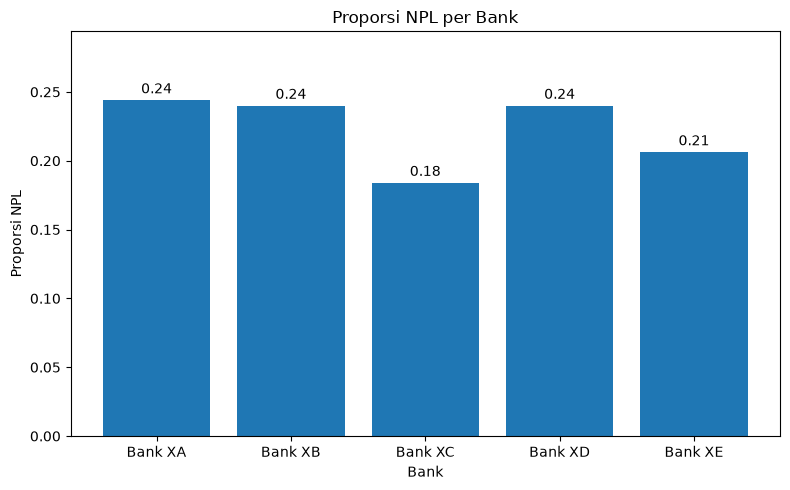

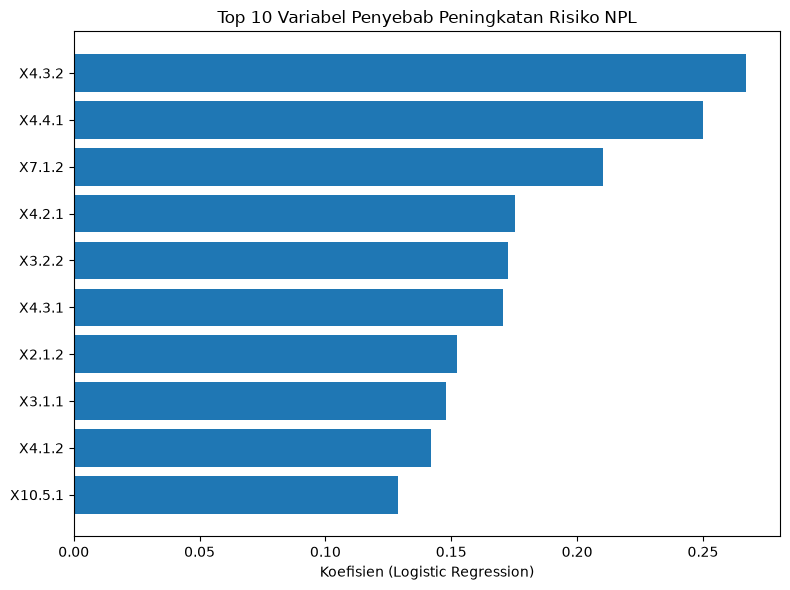

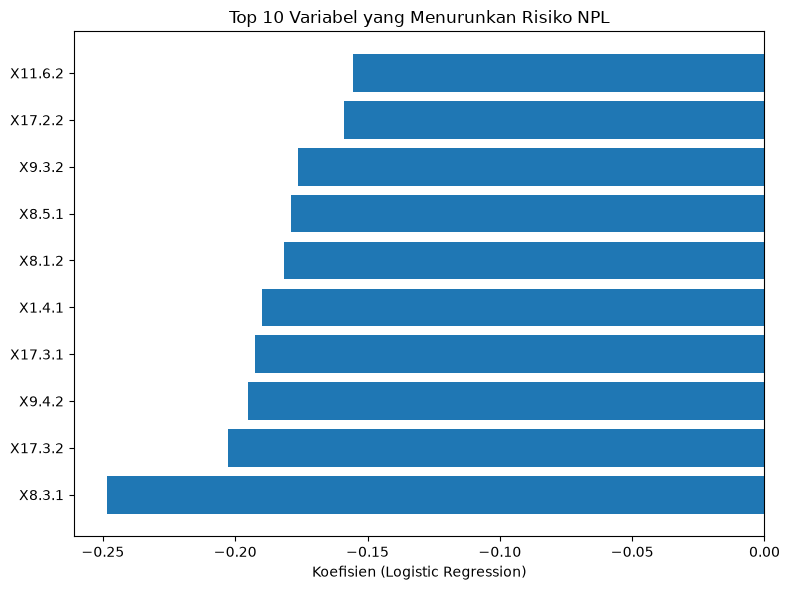

In [6]:
import matplotlib.pyplot as plt

# === PROPORSI NPL PER BANK (DESKRIPTIF) ===
dist = (
    full.groupby(["Nama", "status_kredit"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "Performing (0)", 1: "Non-Performing (1)"})
)

dist["Total"] = dist["Performing (0)"] + dist["Non-Performing (1)"]
dist["Proporsi_NPL"] = dist["Non-Performing (1)"] / dist["Total"]

plt.figure(figsize=(8, 5))
plt.bar(dist.index, dist["Proporsi_NPL"])
plt.title("Proporsi NPL per Bank")
plt.ylabel("Proporsi NPL")
plt.xlabel("Bank")
plt.ylim(0, dist["Proporsi_NPL"].max() + 0.05)
for i, v in enumerate(dist["Proporsi_NPL"]):
    plt.text(i, v + 0.005, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.show()

# === TOP 10 VARIABEL PENYEBAB NPL (KOEFISIEN POSITIF) ===
top10 = coef_df.head(10).sort_values("Koefisien", ascending=True)  # sort biar barh dari kecil ke besar

plt.figure(figsize=(8, 6))
plt.barh(top10["Variabel"], top10["Koefisien"])
plt.title("Top 10 Variabel Penyebab Peningkatan Risiko NPL")
plt.xlabel("Koefisien (Logistic Regression)")
plt.tight_layout()
plt.show()

# === TOP 10 VARIABEL PELINDUNG (KOEFISIEN NEGATIF TERBESAR) ===
bottom10 = coef_df.tail(10).sort_values("Koefisien", ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(bottom10["Variabel"], bottom10["Koefisien"])
plt.title("Top 10 Variabel yang Menurunkan Risiko NPL")
plt.xlabel("Koefisien (Logistic Regression)")
plt.tight_layout()
plt.show()

In [7]:
# Create table of key variables with interpreted names
data = [
    ["X4.4.1", "Procedural Fairness", "Fairness (X4)", "Meningkatkan Risiko NPL (Positif)"],
    ["X4.3.2", "Distributive Fairness - Item 2", "Fairness (X4)", "Meningkatkan Risiko NPL (Positif)"],
    ["X7.1.2", "Behavioral Control - Item 2", "Behavioral Control (X7)", "Meningkatkan Risiko NPL (Positif)"],
    ["X4.2.1", "Informational Fairness - Item 1", "Fairness (X4)", "Meningkatkan Risiko NPL (Positif)"],
    ["X4.3.1", "Distributive Fairness - Item 1", "Fairness (X4)", "Meningkatkan Risiko NPL (Positif)"],
    ["X3.2.2", "Interest - Item 2", "Fashions / Lifestyle (X3)", "Meningkatkan Risiko NPL (Positif)"],
    ["X17.3.1", "Socioeconomic / Family Problems - Item 1", "Condition (X17)", "Menurunkan Risiko NPL (Negatif)"],
    ["X9.4.2", "Achievement-Striving - Item 2", "Conscientiousness (X9)", "Menurunkan Risiko NPL (Negatif)"],
    ["X17.3.2", "Socioeconomic / Family Problems - Item 2", "Condition (X17)", "Menurunkan Risiko NPL (Negatif)"],
    ["X8.3.1", "Emotionality - Item 1", "Openness to Experience (X8)", "Menurunkan Risiko NPL (Negatif)"]
]

df_vars = pd.DataFrame(data, columns=["Kode Variabel", "Nama Indikator", "Variabel Utama", "Dampak terhadap NPL"])
df_vars

,Kode Variabel,Nama Indikator,Variabel Utama,Dampak terhadap NPL
0,X4.4.1,Procedural Fairness,Fairness (X4),Meningkatkan Risiko NPL (Positif)
1,X4.3.2,Distributive Fairness - Item 2,Fairness (X4),Meningkatkan Risiko NPL (Positif)
2,X7.1.2,Behavioral Control - Item 2,Behavioral Control (X7),Meningkatkan Risiko NPL (Positif)
3,X4.2.1,Informational Fairness - Item 1,Fairness (X4),Meningkatkan Risiko NPL (Positif)
4,X4.3.1,Distributive Fairness - Item 1,Fairness (X4),Meningkatkan Risiko NPL (Positif)
5,X3.2.2,Interest - Item 2,Fashions / Lifestyle (X3),Meningkatkan Risiko NPL (Positif)
6,X17.3.1,Socioeconomic / Family Problems - Item 1,Condition (X17),Menurunkan Risiko NPL (Negatif)
7,X9.4.2,Achievement-Striving - Item 2,Conscientiousness (X9),Menurunkan Risiko NPL (Negatif)
8,X17.3.2,Socioeconomic / Family Problems - Item 2,Condition (X17),Menurunkan Risiko NPL (Negatif)
9,X8.3.1,Emotionality - Item 1,Openness to Experience (X8),Menurunkan Risiko NPL (Negatif)
